In [1]:
import sys
print(sys.executable)

/home/shubhayu18/Documents/football-analysis/.venv/bin/python


In [9]:
import pandas as pd
from pathlib import Path

csv_path = Path("data/raw/epl_2024_25.csv")

print("CSV exists:", csv_path.exists())

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
df.head()

CSV exists: True
Dataset shape: (380, 120)


,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,BFECAHH,BFECAHA
0,E0,16/08/2024,20:00,Man United,Fulham,1,0,H,0,0,...,1.86,2.07,1.83,2.11,1.88,2.11,1.82,2.05,1.90,2.08
1,E0,17/08/2024,12:30,Ipswich,Liverpool,0,2,A,0,0,...,2.05,1.88,2.04,1.90,2.20,2.00,1.99,1.88,2.04,1.93
2,E0,17/08/2024,15:00,Arsenal,Wolves,2,0,H,1,0,...,2.02,1.91,2.00,1.90,2.05,1.93,1.99,1.87,2.02,1.96
3,E0,17/08/2024,15:00,Everton,Brighton,0,3,A,0,1,...,1.87,2.06,1.86,2.07,1.92,2.10,1.83,2.04,1.88,2.11
4,E0,17/08/2024,15:00,Newcastle,Southampton,1,0,H,1,0,...,1.87,2.06,1.88,2.06,1.89,2.10,1.82,2.05,1.89,2.10


In [10]:
# 1. Display the first five rows
df.head()
# 2. Find the number of rows and columns
df.shape
# 3. Display all column names
df.columns.tolist()
# 4. Inspect column types and non-null counts
df.info()
# 5. Count missing values in each column
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Columns: 120 entries, Div to BFECAHA
dtypes: float64(96), int64(16), str(8)
memory usage: 356.4 KB


Div         0
Date        0
Time        0
HomeTeam    0
AwayTeam    0
           ..
MaxCAHA     0
AvgCAHH     0
AvgCAHA     0
BFECAHH     0
BFECAHA     0
Length: 120, dtype: int64

In [18]:
print("total missing values: ", df.isnull().sum().sum())

missing = df.isnull().sum()
print("\nmissing columns:\n")
print(missing[missing > 0])

print("duplicate: \n",df.duplicated().sum())

df[
    ["HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"]
    ].head(10)

total missing values:  1440

missing columns:

BWH        141
BWD        141
BWA        141
BFH          1
BFD          1
BFA          1
WHH         91
WHD         91
WHA         91
1XBH         9
1XBD         9
1XBA         9
P>2.5        3
P<2.5        3
BFE>2.5      3
BFE<2.5      3
BWCH       141
BWCD       141
BWCA       141
WHCH        91
WHCD        91
WHCA        91
PC>2.5       3
PC<2.5       3
dtype: int64
duplicate: 
 0


,HomeTeam,AwayTeam,FTHG,FTAG,FTR
0,Man United,Fulham,1,0,H
1,Ipswich,Liverpool,0,2,A
2,Arsenal,Wolves,2,0,H
3,Everton,Brighton,0,3,A
4,Newcastle,Southampton,1,0,H
5,Nott'm Forest,Bournemouth,1,1,D
6,West Ham,Aston Villa,1,2,A
7,Brentford,Crystal Palace,2,1,H
8,Chelsea,Man City,0,2,A
9,Leicester,Tottenham,1,1,D


In [21]:
match_columns = [
    "Date",
    "HomeTeam",
    "AwayTeam",
    "FTHG",
    "FTAG",
    "FTR",
    "HS",
    "AS",
    "HST",
    "AST",
]

matches = df[match_columns].copy()

print("original shape: ", df.shape)
print("analysis shape: ", matches.shape)

print("\nMissing values in selected columns:")
print(matches.isnull().sum())

matches.head()

original shape:  (380, 120)
analysis shape:  (380, 10)

Missing values in selected columns:
Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
HS          0
AS          0
HST         0
AST         0
dtype: int64


,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HS,AS,HST,AST
0,16/08/2024,Man United,Fulham,1,0,H,14,10,5,2
1,17/08/2024,Ipswich,Liverpool,0,2,A,7,18,2,5
2,17/08/2024,Arsenal,Wolves,2,0,H,18,9,6,3
3,17/08/2024,Everton,Brighton,0,3,A,9,10,1,5
4,17/08/2024,Newcastle,Southampton,1,0,H,3,19,1,4


In [25]:
matches["TotalGoals"] = matches["FTHG"] + matches["FTAG"]
matches["GoalDifference"] = matches["FTHG"] - matches["FTAG"]

print("\n missing values\n")
print(matches.isnull().sum())

matches[
    ["HomeTeam", "AwayTeam", "FTHG", "FTAG",
     "TotalGoals", "GoalDifference"]
].head(10)


 missing values

Date              0
HomeTeam          0
AwayTeam          0
FTHG              0
FTAG              0
FTR               0
HS                0
AS                0
HST               0
AST               0
TotalGoals        0
GoalDifference    0
dtype: int64


,HomeTeam,AwayTeam,FTHG,FTAG,TotalGoals,GoalDifference
0,Man United,Fulham,1,0,1,1
1,Ipswich,Liverpool,0,2,2,-2
2,Arsenal,Wolves,2,0,2,2
3,Everton,Brighton,0,3,3,-3
4,Newcastle,Southampton,1,0,1,1
5,Nott'm Forest,Bournemouth,1,1,2,0
6,West Ham,Aston Villa,1,2,3,-1
7,Brentford,Crystal Palace,2,1,3,1
8,Chelsea,Man City,0,2,2,-2
9,Leicester,Tottenham,1,1,2,0


In [27]:
print(matches["FTR"].value_counts())

FTR
H    155
A    132
D     93
Name: count, dtype: int64


In [54]:
unique_T = sorted(set(matches["HomeTeam"]))

total_matches_played = {}

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["HomeTeam"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            cnt1 += 1
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            cnt2 += 1
        else:
            continue
    total_played = cnt1 + cnt2
    total_matches_played[unique_T[i]] = total_played

In [50]:
total_matches_won = {}
total_matches_lost = {}
total_matches_drawn = {}

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["FTR"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "H":
                cnt1 += 1
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "A":
                cnt2 += 1
        else:
            continue
    total_won = cnt1 + cnt2
    total_matches_won[unique_T[i]] = total_won

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["FTR"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "A":
                cnt1 += 1
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "H":
                cnt2 += 1
        else:
            continue
    total_lost = cnt1 + cnt2
    total_matches_lost[unique_T[i]] = total_lost

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["FTR"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "D":
                cnt1 += 1
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "D":
                cnt2 += 1
        else:
            continue
    total_drawn = cnt1 + cnt2
    total_matches_drawn[unique_T[i]] = total_drawn

In [47]:
GF= {} #goals for
GA = {} #goals against

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["HomeTeam"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            cnt1 = cnt1 + int(matches["FTHG"].iloc[j])
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            cnt2 = cnt2 + int(matches["FTAG"].iloc[j])
        else:
            continue
    total_GF = cnt1 + cnt2
    GF[unique_T[i]] = total_GF
print(GF)
print("\n")

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["HomeTeam"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            cnt1 = cnt1 + int(matches["FTAG"].iloc[j])
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            cnt2 = cnt2 + int(matches["FTHG"].iloc[j])
        else:
            continue
    total_GA = cnt1 + cnt2
    GA[unique_T[i]] = total_GA
print(GA)

{'Arsenal': 69, 'Aston Villa': 58, 'Bournemouth': 58, 'Brentford': 66, 'Brighton': 66, 'Chelsea': 64, 'Crystal Palace': 51, 'Everton': 42, 'Fulham': 54, 'Ipswich': 36, 'Leicester': 33, 'Liverpool': 86, 'Man City': 72, 'Man United': 44, 'Newcastle': 68, "Nott'm Forest": 58, 'Southampton': 26, 'Tottenham': 64, 'West Ham': 46, 'Wolves': 54}


{'Arsenal': 34, 'Aston Villa': 51, 'Bournemouth': 46, 'Brentford': 57, 'Brighton': 59, 'Chelsea': 43, 'Crystal Palace': 51, 'Everton': 44, 'Fulham': 54, 'Ipswich': 82, 'Leicester': 80, 'Liverpool': 41, 'Man City': 44, 'Man United': 54, 'Newcastle': 47, "Nott'm Forest": 46, 'Southampton': 86, 'Tottenham': 65, 'West Ham': 62, 'Wolves': 69}


In [49]:
goal_difference = {}

for i in range(len(unique_T)):
    goal_difference[unique_T[i]] = GF[unique_T[i]] - GA[unique_T[i]]

print(goal_difference)


{'Arsenal': 35, 'Aston Villa': 7, 'Bournemouth': 12, 'Brentford': 9, 'Brighton': 7, 'Chelsea': 21, 'Crystal Palace': 0, 'Everton': -2, 'Fulham': 0, 'Ipswich': -46, 'Leicester': -47, 'Liverpool': 45, 'Man City': 28, 'Man United': -10, 'Newcastle': 21, "Nott'm Forest": 12, 'Southampton': -60, 'Tottenham': -1, 'West Ham': -16, 'Wolves': -15}


In [52]:
total_points = {}

for i in range(len(unique_T)):
    total_points[unique_T[i]] = (3*total_matches_won[unique_T[i]]) + (total_matches_drawn[unique_T[i]])

print(total_points)

{'Arsenal': 74, 'Aston Villa': 66, 'Bournemouth': 56, 'Brentford': 56, 'Brighton': 61, 'Chelsea': 69, 'Crystal Palace': 53, 'Everton': 48, 'Fulham': 54, 'Ipswich': 22, 'Leicester': 25, 'Liverpool': 84, 'Man City': 71, 'Man United': 42, 'Newcastle': 66, "Nott'm Forest": 65, 'Southampton': 12, 'Tottenham': 38, 'West Ham': 43, 'Wolves': 42}


In [59]:
league_table = pd.DataFrame({
    "Played": total_matches_played,
    "Wins": total_matches_won,
    "Draws": total_matches_drawn,
    "Losses": total_matches_lost,
    "GF": GF,
    "GA": GA,
    "GD": goal_difference,
    "Points": total_points
})

league_table = league_table.sort_values(
    by=["Points", "GD", "GF"],
    ascending=[False, False, False]
)

display(league_table)



,Played,Wins,Draws,Losses,GF,GA,GD,Points
Liverpool,38,25,9,4,86,41,45,84
Arsenal,38,20,14,4,69,34,35,74
Man City,38,21,8,9,72,44,28,71
Chelsea,38,20,9,9,64,43,21,69
Newcastle,38,20,6,12,68,47,21,66
Aston Villa,38,19,9,10,58,51,7,66
Nott'm Forest,38,19,8,11,58,46,12,65
Brighton,38,16,13,9,66,59,7,61
Bournemouth,38,15,11,12,58,46,12,56
Brentford,38,16,8,14,66,57,9,56


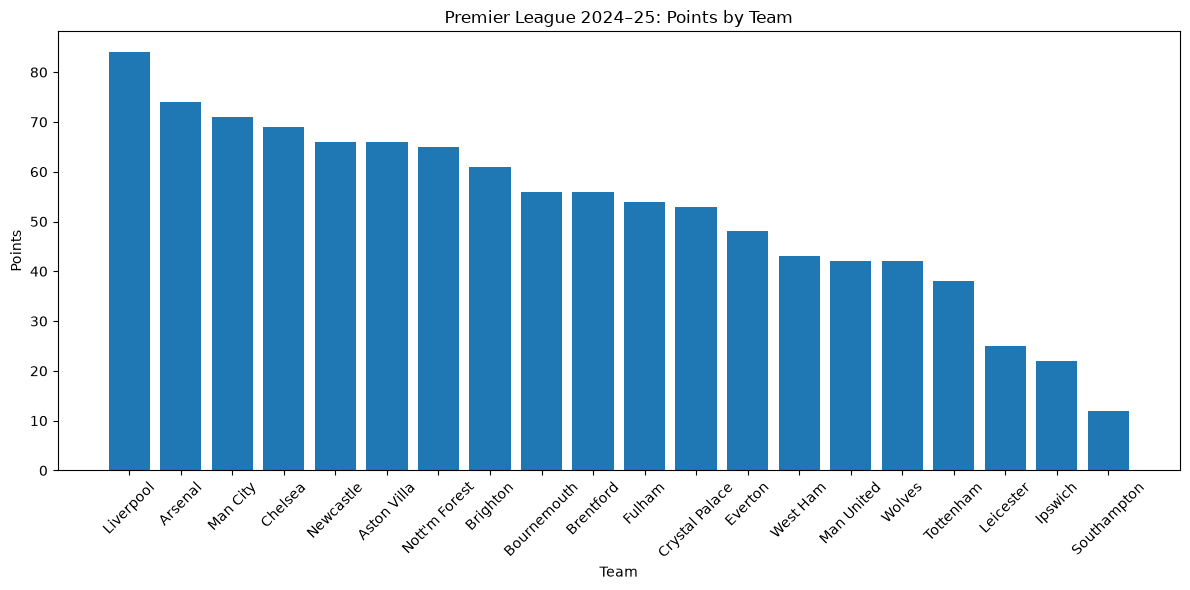

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize = (12,6))

plt.bar(league_table.index, league_table["Points"])

plt.title("Premier League 2024–25: Points by Team")
plt.xlabel("Team")
plt.ylabel("Points")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

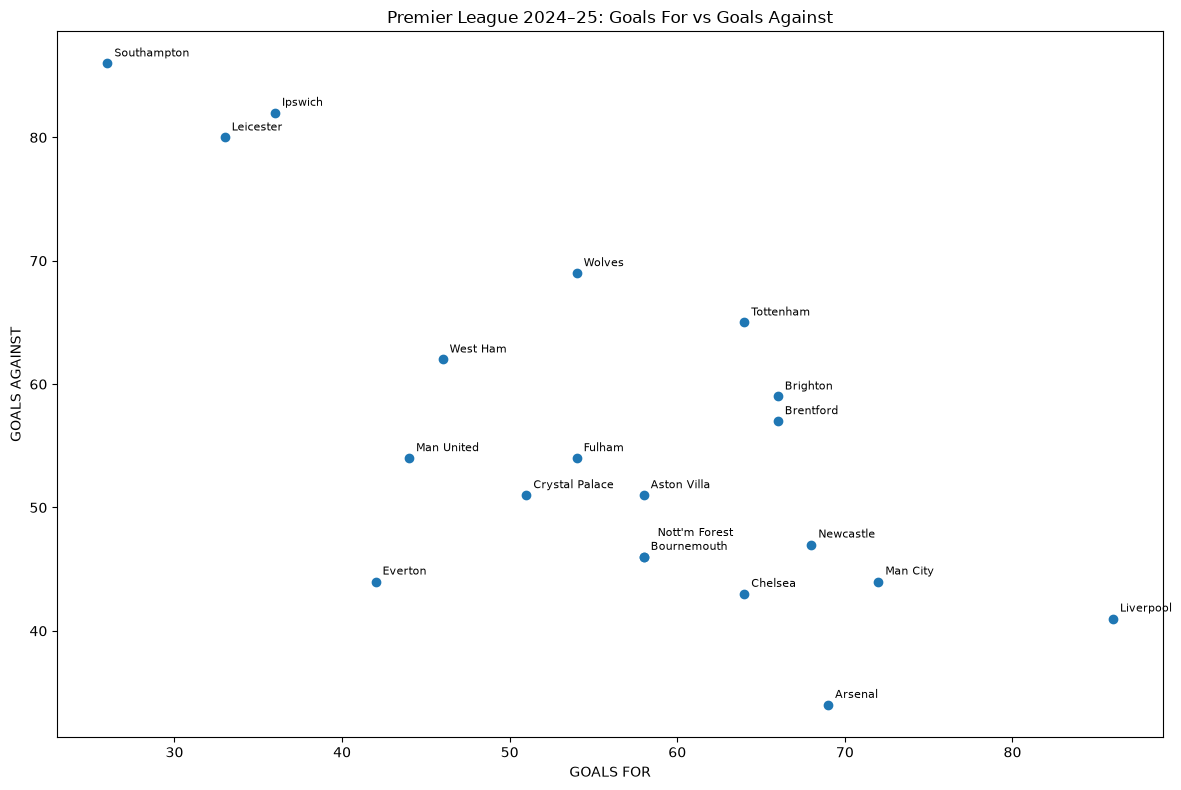

In [92]:
plt.figure(figsize = (12,8))

plt.scatter(league_table["GF"], league_table["GA"])
for team, row in league_table.iterrows():
    offset = (5, 5)

    if team == "Nott'm Forest":
        offset = (10, 15)

    plt.annotate(
        team,
        (row["GF"], row["GA"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=8
)

plt.title("Premier League 2024–25: Goals For vs Goals Against")
plt.xlabel("GOALS FOR")
plt.ylabel("GOALS AGAINST")

plt.tight_layout()
plt.show()

In [ ]:
home_wins = {}
away_wins = {}
home_goals = {}
away_goals = {}

